# Produtividade de soja: média vs mediana

"A produtividade média da safra foi de X sacas por hectare." O número parece simples, mas pode ser calculado de jeitos diferentes, e eles não contam a mesma história quando a distribuição dos municípios é assimétrica.

Este notebook usa a **Produção Agrícola Municipal (PAM) do IBGE** para comparar três resumos do rendimento de soja por município:

| Medida | Conta | Responde |
|---|---|---|
| **Média dos municípios** | soma dos rendimentos ÷ número de municípios | quanto rende um município qualquer, todos com o mesmo peso |
| **Mediana** | o valor do meio | quanto rende o município típico: metade rende mais, metade menos |
| **Produtividade agregada** | produção total ÷ área colhida total | quanto a UF (ou o país) colheu por hectare; é a conta do número oficial |

Roteiro: dados → métricas por UF → média × mediana → distribuições → experimento sem os 5% extremos → média dos municípios × produtividade agregada.

In [1]:
%matplotlib inline
from pathlib import Path
import sys

import numpy as np
import pandas as pd

RAIZ = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src" / "metricas.py").exists())
sys.path.insert(0, str(RAIZ / "src"))

import graficos
import metricas
from coleta_sidra import ler_processado
from graficos import fmt

pd.set_option("display.float_format", lambda x: fmt(x, 2))
pd.set_option("display.max_columns", 20)

## Configuração

`ARQUIVO` aponta para a tabela limpa em `data/processed/`. Sem acesso à API do IBGE, rode `python src/simular.py` e troque pelo arquivo simulado (os gráficos vão para `img/simulado/`, sem sobrescrever os reais).

In [2]:
ANO = 2025
ARQUIVO = RAIZ / "data" / "processed" / f"soja_municipios_{ANO}.csv"
# ARQUIVO = RAIZ / "data" / "processed" / "soja_municipios_simulado.csv"

N_MIN = 20  # UFs com pelo menos N_MIN municípios com soja entram nas comparações
LIMIAR_PCT = 5.0  # destaca UFs em que |média - mediana| passa de 5% da mediana
FRACAO_EXTREMOS = 0.05  # experimento: tirar os 5% de cada cauda
UF_DESTAQUE = "MT"  # primeiro histograma
SALVAR_IMAGENS = True

## 1. Dados

A tabela vem de `src/coleta_sidra.py`: PAM, tabela 5457 do SIDRA, produto Soja (em grão), nível município. Uma linha por município com soja colhida; rendimento em sacas de 60 kg por hectare (sc/ha).

In [3]:
if not ARQUIVO.exists():
    raise FileNotFoundError(
        f"{ARQUIVO.relative_to(RAIZ)} não existe. Rode `python src/coleta_sidra.py` "
        "ou `python src/simular.py` antes."
    )

df = ler_processado(ARQUIVO)
SIMULADO = bool(df["uf"].str.startswith("SIM-").all())
ANO = int(df["ano"].iloc[0])
DIR_IMG = RAIZ / "img" / ("simulado" if SIMULADO else "")


def caminho_imagem(nome):
    return DIR_IMG / nome if SALVAR_IMAGENS else None


aviso = " (dados SIMULADOS)" if SIMULADO else ""
print(f"{len(df):,} municípios com soja colhida em {ANO}{aviso}".replace(",", "."))
print(f"Área colhida: {fmt(df['area_colhida_ha'].sum(), 0)} ha | Produção: {fmt(df['producao_t'].sum(), 0)} t")
df.head()

2.641 municípios com soja colhida em 2025
Área colhida: 47.621.662 ha | Produção: 165.259.014 t


,cod_municipio,municipio,uf,ano,area_colhida_ha,producao_t,rendimento_kg_ha,rendimento_sc_ha
0,1200179,Capixaba,AC,2025,"3.418,00","13.501,00","3.950,00","65,83"
1,1200203,Cruzeiro do Sul,AC,2025,"281,00","826,00","2.940,00","49,00"
2,1200252,Epitaciolândia,AC,2025,"425,00","1.658,00","3.901,00","65,02"
3,1200385,Plácido de Castro,AC,2025,"3.964,00","12.685,00","3.200,00","53,33"
4,1200807,Porto Acre,AC,2025,"1.560,00","5.616,00","3.600,00","60,00"


Na PAM, o rendimento de cada município é a produção dividida pela área colhida, arredondado em kg/ha. Vale conferir, porque a seção 6 depende disso.

In [4]:
diferenca = df["rendimento_kg_ha"] - df["producao_t"] * 1000 / df["area_colhida_ha"]
print(f"Maior diferença entre o rendimento publicado e produção/área: {fmt(diferenca.abs().max(), 2)} kg/ha")

Maior diferença entre o rendimento publicado e produção/área: 0,50 kg/ha


## 2. Métricas por UF

`metricas.resumo` calcula, para cada UF, sobre o rendimento dos municípios (sc/ha):

- `media`, `mediana`, `p25` e `p75` (quartis);
- `media_ponderada_area`: média dos municípios ponderada pela área colhida;
- `agregada`: produção total ÷ área total;
- `dif_media_mediana_pct` e `dif_media_agregada_pct`: quanto a média simples se afasta da mediana e da agregada, em %;
- `assimetria`: coeficiente de assimetria (negativo = cauda à esquerda, de rendimentos baixos).

As comparações usam as UFs com pelo menos `N_MIN` municípios com soja.

In [5]:
resumo = metricas.resumo(df)
brasil = metricas.resumo_total(df, rotulo="Brasil")
principais = resumo.index[resumo["n_municipios"] >= N_MIN].tolist()

participacao = resumo.loc[principais, "producao_t"].sum() / resumo["producao_t"].sum() * 100
print(f"{len(principais)} UFs com pelo menos {N_MIN} municípios; {fmt(participacao)}% da produção.")

colunas = [
    "n_municipios", "media", "mediana", "p25", "p75", "agregada",
    "dif_media_mediana_pct", "dif_media_agregada_pct",
]
tabela = pd.concat([resumo.loc[principais, colunas], brasil[colunas]])
tabela

14 UFs com pelo menos 20 municípios; 99,4% da produção.


,n_municipios,media,mediana,p25,p75,agregada,dif_media_mediana_pct,dif_media_agregada_pct
uf,,,,,,,,
MT,131,"64,04","64,17","61,67","66,47","65,39","-0,20","-2,07"
PR,388,"57,24","58,33","51,67","63,92","60,76","-1,87","-5,79"
GO,233,"64,59","65,00","60,00","68,33","66,14","-0,63","-2,34"
RS,434,"37,60","36,18","30,00","45,00","33,53","3,92","12,14"
MS,78,"50,44","49,08","39,25","59,77","51,28","2,78","-1,64"
MG,302,"62,35","62,50","60,00","65,00","64,48","-0,24","-3,31"
BA,24,"58,72","63,18","54,24","66,75","68,71","-7,06","-14,54"
TO,107,"55,84","55,02","50,00","62,00","59,05","1,49","-5,44"
SP,470,"54,29","55,00","49,00","61,67","57,31","-1,29","-5,27"


In [6]:
# Tabela completa (todas as UFs + Brasil) para quem quiser usar fora do notebook
nome_resumo = "resumo_uf_simulado.csv" if SIMULADO else f"resumo_uf_{ANO}.csv"
pd.concat([resumo, brasil]).round(4).to_csv(RAIZ / "data" / "processed" / nome_resumo)
print(f"Salvo: data/processed/{nome_resumo}")

Salvo: data/processed/resumo_uf_2025.csv


## 3. Média × mediana

Numa distribuição simétrica, média e mediana praticamente coincidem. Quando há uma cauda, a média vai atrás dela e a mediana fica onde está a maioria dos municípios. O sinal da diferença indica o lado da cauda:

- **negativo** (média abaixo da mediana): cauda de municípios com rendimento baixo, como quebra por seca ou áreas marginais;
- **positivo** (média acima da mediana): cauda de municípios com rendimento alto.

UFs (e Brasil) em que a diferença passa de `LIMIAR_PCT`:

In [7]:
destaques = metricas.destacar(pd.concat([resumo.loc[principais], brasil]), LIMIAR_PCT)
destaques[["n_municipios", "media", "mediana", "dif_media_mediana_pct", "assimetria"]]

,n_municipios,media,mediana,dif_media_mediana_pct,assimetria
uf,,,,,
BA,24,"58,72","63,18","-7,06","-2,08"
PI,37,"51,17","53,90","-5,06","-0,68"
Brasil,2641,"54,51","58,00","-6,02","-0,76"


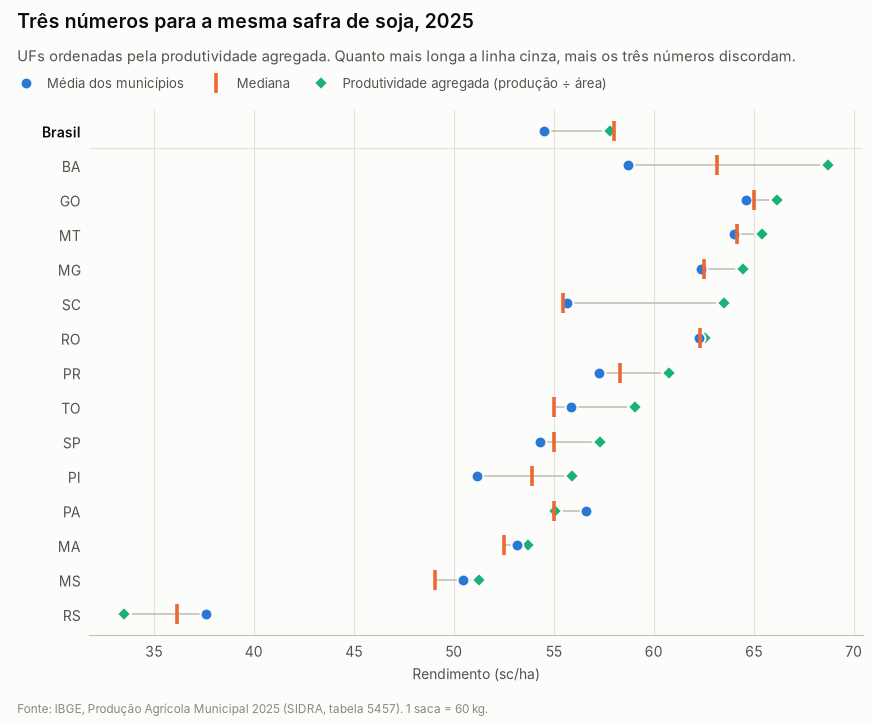

In [8]:
fig = graficos.comparacao_ufs(
    resumo.loc[principais], ano=ANO, total=brasil, simulado=SIMULADO,
    caminho=caminho_imagem("media_mediana_agregada_ufs.png"),
)
fig

## 4. Distribuições

Histograma de `UF_DESTAQUE` e da grande produtora (entre as 10 maiores em produção) com a maior diferença entre média e mediana. Os dois usam o mesmo eixo x, para comparar a dispersão.

In [9]:
if UF_DESTAQUE not in resumo.index:  # ex.: dados simulados
    UF_DESTAQUE = resumo["n_municipios"].idxmax()
grandes = resumo.nlargest(10, "producao_t").index
UF_DISTORCAO = metricas.maior_distorcao(resumo, candidatas=grandes, excluir=(UF_DESTAQUE,))

duas = df.loc[df["uf"].isin([UF_DESTAQUE, UF_DISTORCAO]), "rendimento_sc_ha"]
LIMITES = (np.floor(duas.min() / 10) * 10, np.ceil(duas.max() / 10) * 10)
print(f"Destaque: {UF_DESTAQUE} | Maior distorção entre as grandes: {UF_DISTORCAO}")
resumo.loc[[UF_DESTAQUE, UF_DISTORCAO], ["n_municipios", "media", "mediana", "agregada", "dif_media_mediana_pct"]]

Destaque: MT | Maior distorção entre as grandes: BA


,n_municipios,media,mediana,agregada,dif_media_mediana_pct
uf,,,,,
MT,131,"64,04","64,17","65,39","-0,20"
BA,24,"58,72","63,18","68,71","-7,06"


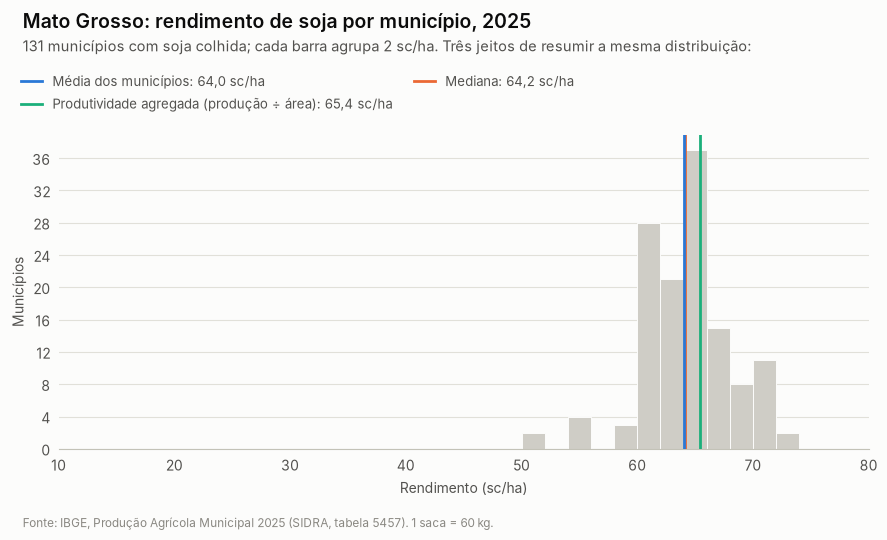

In [10]:
fig = graficos.histograma_uf(
    df, UF_DESTAQUE, limites=LIMITES, simulado=SIMULADO,
    caminho=caminho_imagem(f"histograma_{UF_DESTAQUE.lower()}.png"),
)
fig

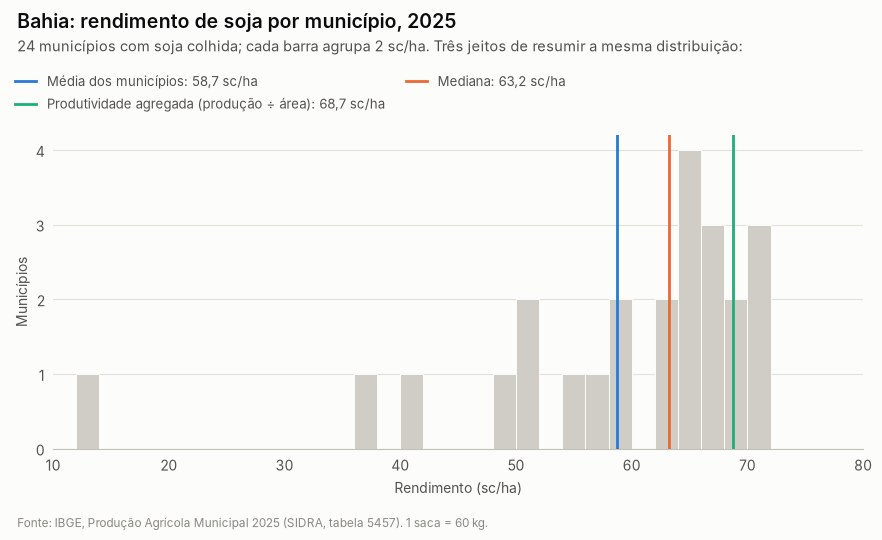

In [11]:
fig = graficos.histograma_uf(
    df, UF_DISTORCAO, limites=LIMITES, simulado=SIMULADO,
    caminho=caminho_imagem(f"histograma_{UF_DISTORCAO.lower()}.png"),
)
fig

O boxplot mostra todas as UFs de uma vez. A caixa vai do P25 ao P75 (a metade central dos municípios), o traço laranja é a mediana e o ponto azul, a média. Média longe do traço indica distribuição assimétrica; caixa larga, municípios muito diferentes entre si.

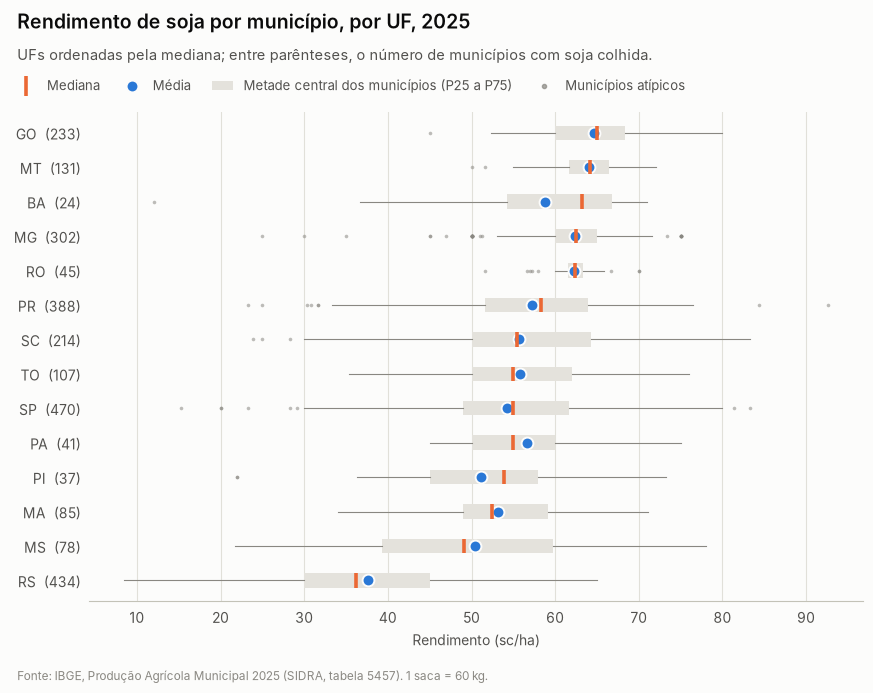

In [12]:
fig = graficos.boxplot_ufs(df, principais, simulado=SIMULADO, caminho=caminho_imagem("boxplot_ufs.png"))
fig

## 5. Experimento: sem os 5% extremos

Recalculamos média e mediana de cada UF sem os municípios acima do percentil 95 da própria UF (os ~5% de maior rendimento). Depois, o mesmo sem os ~5% de menor rendimento (abaixo do percentil 5). Na linha "Brasil", o corte é feito no país inteiro.

Qual das duas medidas se move mais?

In [13]:
def experimento(cauda):
    por_uf = metricas.experimento_extremos(df[df["uf"].isin(principais)], FRACAO_EXTREMOS, cauda)
    pais = metricas.experimento_extremos(df.assign(pais="Brasil"), FRACAO_EXTREMOS, cauda, por="pais")
    return pd.concat([por_uf.loc[principais], pais])


topo, base = experimento("superior"), experimento("inferior")
comparativo = pd.DataFrame(
    {
        "removidos (topo)": topo["removidos"],
        "Δ média (topo)": topo["delta_media"],
        "Δ mediana (topo)": topo["delta_mediana"],
        "removidos (base)": base["removidos"],
        "Δ média (base)": base["delta_media"],
        "Δ mediana (base)": base["delta_mediana"],
    }
)
comparativo

,removidos (topo),Δ média (topo),Δ mediana (topo),removidos (base),Δ média (base),Δ mediana (base)
MT,6,"-0,35","-0,17",6,"0,49","0,50"
PR,20,"-0,98","-0,48",13,"0,89","0,00"
GO,12,"-0,62","-0,83",12,"0,66","1,00"
RS,11,"-0,68","-0,18",20,"1,07","0,82"
MS,4,"-1,47","-0,58",4,"1,24","0,78"
MG,12,"-0,46","-0,50",6,"0,50","0,38"
BA,1,"-0,53","-0,90",2,"3,13","1,36"
TO,5,"-0,83","-0,02",5,"0,85","1,65"
SP,16,"-0,77","-0,33",24,"1,34","0,00"
MA,4,"-0,76","-0,72",5,"1,08","0,98"


In [14]:
for nome, t in [("5% de maior rendimento", topo), ("5% de menor rendimento", base)]:
    ufs = t.drop(index="Brasil")
    mais = int((ufs["delta_media"].abs() > ufs["delta_mediana"].abs()).sum())
    print(
        f"Sem os {nome}: a média se moveu mais que a mediana em {mais} de {len(ufs)} UFs. "
        f"Brasil: média {fmt(t.loc['Brasil', 'delta_media'], 2)} e mediana "
        f"{fmt(t.loc['Brasil', 'delta_mediana'], 2)} sc/ha."
    )

# Distância das caudas até a média do país
r = df["rendimento_sc_ha"]
cauda_alta = r[r > r.quantile(1 - FRACAO_EXTREMOS)]
cauda_baixa = r[r < r.quantile(FRACAO_EXTREMOS)]
print(
    f"\nOs municípios da cauda alta rendem, em média, {fmt(cauda_alta.mean() - r.mean())} sc/ha "
    f"acima da média do país; os da cauda baixa, {fmt(r.mean() - cauda_baixa.mean())} sc/ha abaixo."
)
print("UFs da cauda baixa:", cauda_baixa.groupby(df["uf"]).size().sort_values(ascending=False).head(3).to_dict())

Sem os 5% de maior rendimento: a média se moveu mais que a mediana em 11 de 14 UFs. Brasil: média -1,02 e mediana -1,33 sc/ha.
Sem os 5% de menor rendimento: a média se moveu mais que a mediana em 10 de 14 UFs. Brasil: média 1,49 e mediana 0,33 sc/ha.

Os municípios da cauda alta rendem, em média, 19,4 sc/ha acima da média do país; os da cauda baixa, 31,3 sc/ha abaixo.
UFs da cauda baixa: {'RS': 101, 'SP': 6, 'MS': 3}


Duas leituras:

1. **A mediana não é imune a cortes.** Tirar 5% de um lado sempre a empurra um pouco, porque o "meio" muda de lugar. O que a torna robusta é não depender de *quão* extremos são os municípios retirados.
2. **A média se move na proporção da distância** entre os extremos e o resto. Por isso importa de que lado está a cauda longa: se os piores municípios estão bem mais longe da média do que os melhores, são eles que puxam a média, e é a cauda de baixo que distorce o número de destaque.

## 6. Média dos municípios × produtividade agregada

A produtividade agregada é a média dos municípios **ponderada pela área colhida**; são a mesma conta (a coluna `media_ponderada_area` bate com `agregada`, a menos do arredondamento do rendimento na PAM). A diferença entre a média simples e a agregada vem, então, só do peso: na média simples, um município com 50 ha vale o mesmo que um com 500 mil ha.

Se os municípios com mais área rendem mais, a agregada fica acima da média simples; se rendem menos, abaixo. A correlação de Spearman entre área e rendimento mostra para que lado pende cada UF.

In [15]:
maior_desvio = (resumo["media_ponderada_area"] - resumo["agregada"]).abs().max()
print(f"Maior diferença entre média ponderada pela área e agregada: {fmt(maior_desvio, 3)} sc/ha")

correlacao = metricas.correlacao_area_rendimento(df[df["uf"].isin(principais)])
peso = pd.concat(
    [resumo.loc[principais, ["media", "agregada", "dif_media_agregada_pct"]], correlacao], axis=1
).sort_values("dif_media_agregada_pct")
peso

Maior diferença entre média ponderada pela área e agregada: 0,004 sc/ha


,media,agregada,dif_media_agregada_pct,spearman_area_rendimento
uf,,,,
BA,"58,72","68,71","-14,54","0,56"
SC,"55,65","63,51","-12,37","0,41"
PI,"51,17","55,93","-8,51","0,33"
PR,"57,24","60,76","-5,79","0,34"
TO,"55,84","59,05","-5,44","0,41"
SP,"54,29","57,31","-5,27","0,26"
MG,"62,35","64,48","-3,31","0,33"
GO,"64,59","66,14","-2,34","0,07"
MT,"64,04","65,39","-2,07","0,38"


In [16]:
pequenos = df[df["area_colhida_ha"] < 500]
print(
    f"{len(pequenos)} municípios ({fmt(len(pequenos) / len(df) * 100)}% do total) colheram menos de 500 ha "
    f"e somam {fmt(pequenos['area_colhida_ha'].sum() / df['area_colhida_ha'].sum() * 100, 2)}% da área: "
    "na média simples, pesam como os grandes."
)

457 municípios (17,3% do total) colheram menos de 500 ha e somam 0,21% da área: na média simples, pesam como os grandes.


## 7. Resumo

In [17]:
b = brasil.loc["Brasil"]
print(f"Brasil, {ANO} ({fmt(b['n_municipios'], 0)} municípios):")
print(f"  média dos municípios     {fmt(b['media'])} sc/ha")
print(f"  mediana                  {fmt(b['mediana'])} sc/ha")
print(f"  produtividade agregada   {fmt(b['agregada'])} sc/ha")
print(f"  média vs mediana         {fmt(b['dif_media_mediana_pct'])}%")
for uf in [UF_DESTAQUE, UF_DISTORCAO]:
    u = resumo.loc[uf]
    print(f"{uf}: média {fmt(u['media'])} | mediana {fmt(u['mediana'])} | agregada {fmt(u['agregada'])} sc/ha")

Brasil, 2025 (2.641 municípios):
  média dos municípios     54,5 sc/ha
  mediana                  58,0 sc/ha
  produtividade agregada   57,8 sc/ha
  média vs mediana         -6,0%
MT: média 64,0 | mediana 64,2 | agregada 65,4 sc/ha
BA: média 58,7 | mediana 63,2 | agregada 68,7 sc/ha


### Como ler (PAM 2025, dados versionados neste repositório)

- **No Brasil, a média dos municípios (54,5 sc/ha) ficou cerca de 6% abaixo da mediana (58,0) e da produtividade agregada (57,8).** Quem puxa a média para baixo é a cauda de rendimentos baixos: 101 dos 120 municípios abaixo do percentil 5 estão no Rio Grande do Sul, que teve quebra por estiagem na safra 2024/25.
- **Em Mato Grosso, os três números quase coincidem** (64,0, 64,2 e 65,4 sc/ha): distribuição concentrada, sem cauda relevante. Ali, qualquer um dos três serve de resumo.
- **Na Bahia, cada número conta uma história**: média 58,7, mediana 63,2 e agregada 68,7 sc/ha. Sete municípios do oeste baiano concentram 97% da área e rendem entre 62 e 71 sc/ha; um punhado de municípios pequenos, com 12 a 50 sc/ha, derruba a média simples.
- **No Rio Grande do Sul, a ordem se inverte**: a agregada (33,5) fica abaixo da mediana (36,2) e da média (37,6), porque os municípios com mais área renderam menos.
- **Sem os 5% de menor rendimento, a média do país sobe 1,5 sc/ha e a mediana, 0,3.** Sem os 5% de maior rendimento, a média cai 1,0 e a mediana, 1,3. A cauda de cima é curta (fica a 19 sc/ha da média); a de baixo é longa (31 sc/ha).

Moral: antes de comparar "produtividades médias", vale perguntar qual das três contas está na mesa e olhar a distribuição.